In [86]:
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import csv
import os
import scienceplots
## load the mining distribution from the file

real_distribution = np.loadtxt("real_distribution_69.txt") # the simulated distribution used in the paper
# real_distribution = np.loadtxt("real_distribution_519.txt") # the longer tail distribution as presented in the appendix
# real_distribution = np.loadtxt("real_distribution_decentralized.txt") # the decentralized distribution without real-world data



In [ ]:
# Real-World Hash Power Distribution Generator (Based on Jan 1, 2026 Data). No need to run this if 'real_distribution_69.txt' is available.
# substitute num_unknown_miners=50 with num_unknown_miners=500 to generate the longer tail distribution as presented in the appendix.

def generate_realistic_bitcoin_distribution(known_pools, unknown_total_hash, num_unknown_miners=500, exponent=1.5):
    """
    Combines known large pool data with a synthetically generated 'long tail' 
    of small miners following a Power Law (Zipf) distribution.
    """
    # 1. Generate the Zipf distribution for the tail
    tail_raw = [1.0 / (k ** exponent) for k in range(1, num_unknown_miners + 1)]
    
    # 2. Normalize the tail so its sum exactly equals the unknown_total_hash
    tail_sum = sum(tail_raw)
    tail_normalized = [(val / tail_sum) * unknown_total_hash for val in tail_raw]
    
    # 3. Combine known pools with the generated tail
    full_distribution = known_pools + tail_normalized
    
    # 4. Final normalization just to prevent floating point drift
    total_network = sum(full_distribution)
    
    # Return sorted (ascending) list as required by our Func A and Func B logic
    return sorted([p / total_network for p in full_distribution])

# --- Extracted Data (Converted to decimals) ---
# We exclude the 'Unknown' (1.64%) from this list, as we will generate it dynamically.
known_pools_jan_2026 = [
    0.2975, # Foundry USA
    0.1623, # AntPool
    0.1111, # ViaBTC
    0.1068, # F2Pool
    0.0822, # SpiderPool
    0.0524, # MARA Pool
    0.0465, # SecPool
    0.0284, # Binance Pool
    0.0260, # Luxor
    0.0186, # SBI Crypto
    0.0167, # OCEAN
    0.0153, # BraiinsPool
    0.0069, # WhitePool
    0.0036, # Ultimus Pool
    0.0029, # Poolin
    0.0029, # BTC.com
    0.0026, # MiningCore
    0.0007, # NiceHash
    0.0002  # KanoPool
]

unknown_hash_jan_2026 = 1 - sum(known_pools_jan_2026) # The 1.64% Unknown slice

# --- Generate the final distribution ---
# Assuming the 1.64% unknown hash power represents 500 tiny distinct entities/solo miners
# You can change `num_unknown_miners` to test different scenarios!
real_distribution = generate_realistic_bitcoin_distribution(
    known_pools=known_pools_jan_2026, 
    unknown_total_hash=unknown_hash_jan_2026, 
    num_unknown_miners=50,
)

# --- Output Analysis ---
print(f"Total N (distinct mining entities): {len(real_distribution)}")
print(f"Largest pool (Foundry): {real_distribution[-1]*100:.2f}%")
print(f"Smallest solo miner (end of tail): {real_distribution[0]*100:.8f}%")
print(f"All miners sorted (descending): {[f'{p*100:.4f}%' for p in sorted(real_distribution, reverse=True)]}")
print(f"Total Distribution Sum: {sum(real_distribution):.5f}")
np.savetxt("real_distribution_69.txt", real_distribution)

Total N (distinct mining entities): 519
Largest pool (Foundry): 29.75%
Smallest solo miner (end of tail): 0.00005814%
All miners sorted (descending): ['29.7500%', '16.2300%', '11.1100%', '10.6800%', '8.2200%', '5.2400%', '4.6500%', '2.8400%', '2.6000%', '1.8600%', '1.6700%', '1.5300%', '0.6900%', '0.6500%', '0.3600%', '0.2900%', '0.2900%', '0.2600%', '0.2298%', '0.1251%', '0.0813%', '0.0700%', '0.0581%', '0.0442%', '0.0351%', '0.0287%', '0.0241%', '0.0206%', '0.0200%', '0.0178%', '0.0156%', '0.0139%', '0.0124%', '0.0112%', '0.0102%', '0.0093%', '0.0085%', '0.0078%', '0.0073%', '0.0068%', '0.0063%', '0.0059%', '0.0055%', '0.0052%', '0.0049%', '0.0046%', '0.0044%', '0.0042%', '0.0040%', '0.0038%', '0.0036%', '0.0034%', '0.0033%', '0.0031%', '0.0030%', '0.0029%', '0.0028%', '0.0027%', '0.0026%', '0.0025%', '0.0024%', '0.0023%', '0.0022%', '0.0022%', '0.0021%', '0.0020%', '0.0020%', '0.0019%', '0.0018%', '0.0018%', '0.0017%', '0.0017%', '0.0016%', '0.0016%', '0.0016%', '0.0015%', '0.0015%'

In [5]:
# A more decentralized distribution generator without real-world data. No need to run this if 'real_distribution_decentralized.txt' is available.

def generate_decentralized_distribution(num_miners=500, zipf_exponent=0.85):
    """
    Generates a realistic decentralized mining distribution using a flat power law.
    Returns a sorted array (ascending) summing to 1.0.
    """
    # 1. Generate the raw Zipf values: 1/1^s, 1/2^s, 1/3^s ... 1/N^s
    raw_dist = [1.0 / (k ** zipf_exponent) for k in range(1, num_miners + 1)]
    
    # 2. Normalize so the sum is exactly 1.0 (100% of hashpower)
    total_hash = sum(raw_dist)
    normalized_dist = [p / total_hash for p in raw_dist]
    
    # 3. Return sorted ascending (required by our HTLC functions)
    return sorted(normalized_dist)

# ==========================================
# Generate and verify the stats
# ==========================================
real_distribution = generate_decentralized_distribution(num_miners=500, zipf_exponent=0.85)

print("--- Decentralized Network Stats ---")
print(f"Total distinct miners (N): {len(real_distribution)}")
print(f"Largest single miner:      {real_distribution[-1] * 100:.2f}%")
print(f"Top 5 miners combined:     {sum(real_distribution   [-5:]) * 100:.2f}%")
print(f"Smallest solo miner:       {real_distribution[0] * 100:.6f}%")
np.savetxt("real_distribution_decentralized.txt", real_distribution)

--- Decentralized Network Stats ---
Total distinct miners (N): 500
Largest single miner:      9.23%
Top 5 miners combined:     23.17%
Smallest solo miner:       0.046883%


In [ ]:
# This code calculates the FB-HTLC timeout according to their approximated bound, which is not used for current experiments.
# ==========================================

def calculate_approx_T(dep, feeA, miners):
    """
    Calculates the approximate required Timeout (T) using the formula:
    T > log_{1 - p_w}(pun/dep)
    """
    pun = feeA
    # p_w is the sum of miners whose raw expected payout is less than punishment
    p_w = sum(p for p in miners if p < (pun / dep))
    
    if p_w == 0:
        return float('inf') # No miner refuses, censorship is guaranteed
    if p_w == 1 or p_w >= (1 - 1e-9):
        return 1 # Everyone refuses immediately
    # print("p_w is:", p_w)
    # Calculate T > log_{1 - p_w} (pun/dep)
    # Using change of base: log_b(x) = ln(x) / ln(b)
    try:
        T_approx = math.log(pun / dep) / math.log(1 - p_w)
        # We need T strictly greater than the result, so we use floor() + 1
        return math.floor(T_approx) + 1
    except ValueError:
        # If pun/dep >= 1, log is positive but denominator is negative -> negative T. 
        # In this case, T=1 is sufficient.
        return 1

In [ ]:
#This function returns the expected number of distinct miners given a distribution and a timeout T. 
def expected_distinct_miners(miners, T):
    """
    Calculates kappa: the expected number of distinct miners 
    who will mine at least one block over a period of T blocks.
    Rounded up to the nearest whole integer to strictly preserve security.
    We use ceil here but floor+1 for T since T needs to be strictly greater but kappa can be equal.
    """
    N = len(miners)
    # Formula: N - sum((1 - p_i)^T)
    kappa = N - sum((1 - p) ** T for p in miners)
    return math.ceil(kappa)

In [18]:
expected_distinct_miners(real_distribution, 20)

9

In [80]:
# this function plots the growth of expected distinct miners (kappa) as a function of timeout T, using the provided miner distribution. 
def plot_kappa_trend_linear(miners, max_blocks=5000):
    N = len(miners)
    plt.style.use(['science', 'ieee', 'grid'])
    # Calculate every single point
    T_values = list(range(1, max_blocks + 1))
    kappa_values = [expected_distinct_miners(miners, T) for T in T_values]

    plt.figure(figsize=(6,3.6 ), dpi=120)
    
    # Plot the curve
    plt.plot(T_values, kappa_values, color='#1f77b4', linewidth=2.5)
    
    # # Add Asymptote
    # plt.axhline(y=N, color="#ffffff", linestyle='--', linewidth=2, 
    #             label=f'Absolute Maximum (N={N})')

    # Formatting
    # plt.title('Growth of Expected Number of Distinct Miners vs. Time Interval', fontsize=14, fontweight='bold')
    plt.xlabel('Time Interval in Blocks - Logarithmic Scale', fontsize=12)
    plt.ylabel(r'$\kappa$', fontsize=12)
    plt.ylim(0, 70) 

    
    # Customizing the X-axis ticks so they are easy to read
    plt.xticks([1, 300, 600, 1000, 2000, 5000], ['1', '300', '600', '1,000', '2,000', '5,000'])
    plt.tick_params(axis='x', which='major', labelsize=9)
    # plt.tick_params(axis='x', which='minor', labelsize=6)
    
    # Grids
    plt.grid(True, which='major', linestyle='-', alpha=0.5)
    plt.grid(True, which='minor', linestyle=':', alpha=0.2)
    
    # plt.legend(loc='lower right', fontsize=11)
    plt.tight_layout()
    plt.savefig('kappa-linear-519.pdf', format='pdf', bbox_inches='tight')
    plt.show()

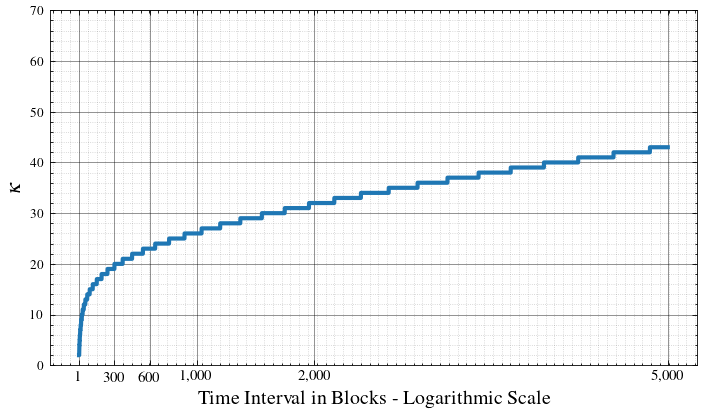

In [81]:
plot_kappa_trend_linear(real_distribution, max_blocks=5000)

In [70]:
# Print a few sanity check points
print("Data Check for 5000 blocks:")
print(f"T = 1    -> Kappa = {expected_distinct_miners(real_distribution, 1):.2f}")
print(f"T = 144  -> Kappa = {expected_distinct_miners(real_distribution, 144):.2f} (1 Day)")
print(f"T = 1000 -> Kappa = {expected_distinct_miners(real_distribution, 1000):.2f} (~1 Week)")
print(f"T = 5000 -> Kappa = {expected_distinct_miners(real_distribution, 5000):.2f} (~1 Month)")
print(f"T = 10000 -> Kappa = {expected_distinct_miners(real_distribution, 9643):.2f} (~3 Months)")

Data Check for 5000 blocks:
T = 1    -> Kappa = 1.00
T = 144  -> Kappa = 91.00 (1 Day)
T = 1000 -> Kappa = 313.00 (~1 Week)
T = 5000 -> Kappa = 487.00 (~1 Month)
T = 10000 -> Kappa = 500.00 (~3 Months)


In [11]:
## Neon-Tight
def expected_escalating_bribe_cost(miners, Delta, pun, dep, col):
    """
    Calculates the exact expected total cost for Bob to bribe the network
    during an escalating punishment phase of length Delta.
    """
    total_expected_cost = 0.0
    
    for p_i in miners:
        expected_payout_for_miner_i = 0.0
        
        # Calculate expected payout for this specific miner
        for t in range(1, Delta + 1):
            # Probability that block t is the LAST block this miner finds
            prob_highest_block_is_t = p_i * ((1 - p_i) ** (Delta - t))
            
            # The payout the attacker must match if block t is the highest
            theoretical_payout = (2 ** (t - 1)) * pun
            actual_payout_t = min(theoretical_payout, dep+col)
            # payout_at_t = (2 ** (t - 1)) * pun
            
            expected_payout_for_miner_i += prob_highest_block_is_t * actual_payout_t
            
        total_expected_cost += expected_payout_for_miner_i
        
    return total_expected_cost

def calculate_T_bribe_escalating_tight(dep, pun, miners, col, fee_A, T1):
    """
    Finds the minimum Delta (T2) using the exact expected statistical cost.
    """       
    Delta = 1
    kappa_A = expected_distinct_miners(miners, T1)
    while True:
        # Get the exact expected cost for this Delta
        required_total_bribe = expected_escalating_bribe_cost(miners, Delta, pun, dep, col)
        # print(f"Bribery now requires {required_total_bribe:.6f}.")
        required_total_bribe = round(required_total_bribe, 6) # Round to 6 decimal places for cleaner output
        
        if required_total_bribe >= dep - kappa_A * fee_A: ## - bribeA?
            return Delta
            
        Delta += 1

In [93]:
##Main function for all two-phase calculations. 
def calculate_two_phase_pun(miners, T1, fee_A, col, d1=True):
    """
    Calculates the dynamic punishment (pun) derived from the Phase 1 fixed length (T1).
    """
    kappa_A = expected_distinct_miners(miners, T1)
    censA = kappa_A * fee_A
    if d1:
        pun = 2 * (col + censA)
    else:
        pun = col + censA
    return pun

def calculate_T_bribe_kappa(dep, pun, fee_A, T1, miners, col, escalating=False, he=False):
    """
    Finds the minimum T such that the total cost to bribe all expected 
    distinct miners (kappa * pun) strictly exceeds the available bribe (dep).
    """
    N = len(miners)
    kappa_A = expected_distinct_miners(miners, T1)
    
    # Edge Case Check: If the attacker can afford to bribe EVERY miner, 
    # no T will ever be safe under this specific bounding logic.
    if N * pun <= dep and not escalating:
        # print(f"Warning: dep ({dep}) is large enough to bribe all {N} miners (cost: {N * pun}).")
        return float('inf') 
    
    if he:
        # for HE-HTLC, we want to calculate the kappa from the given col, dep and feeA according to their relationship: col >= dep/(kappa-1) + feeA
        # rearranging gives us kappa >= (dep/(col-feeA)) + 1
        # Since He-HTLC demands kappa >=2, this gives us a natural lower bound for collateral whenever a dep is set. If we want to try 5%, we need to start at dep=30.
        if col <= fee_A:
            return float('inf') # Impossible case, collateral must be greater than feeA to have any valid kappa.
        kappa_target = math.ceil((dep / (col - fee_A)) + 1)
        # print(f"HE-HTLC Case: Calculated kappa based on col and dep is {kappa_target}.")
        if kappa_target > N or kappa_target < 2:
            print(f"Warning: Calculated kappa target ({kappa_target}) exceeds total number of miners ({N}).")
            return float('inf')
    
    T = 1
    while True:
        kappa = expected_distinct_miners(miners, T)
        if escalating: #below are loose bounds assuming some best case for Bob. We have another function below for the expectation calculation of the escalating case.
            # required_total_bribe = (2**(T-1)) * pun # Global lower bound regardless of mining power distribution
            # The sum of 2^0 + 2^1 + ... + 2^(k-2) is (2^(kappa-1) - 1)
            geometric_sum = (2**(kappa - 1)) - 1
            final_payout = (2**(T - 1)) * pun
            final_payout = min(final_payout, dep+col)
            required_total_bribe = final_payout + geometric_sum * pun
        elif he:
            required_total_bribe = -100 # to prevent accidentally exiting the loop.
            if kappa >= kappa_target:
                # print(f"HE-HTLC Case: At T={T}, kappa={kappa} meets the required kappa_target={kappa_target}.")
                return T
        else:
            required_total_bribe = kappa * pun

        # If the required bribe exceeds the deposit, the attack is unfundable
        if required_total_bribe >= dep - kappa_A * fee_A: ## - bribeA?
            # print(f"HE-HTLC Case: At T={T}, kappa={kappa} meets the required kappa_target={kappa_target}.")
            # print(f"Bribery now requires {required_total_bribe:.2f}.")
            # print(f"kappa: {kappa}")
            return T
            
        T += 1

def calculate_two_phase_T(dep, fee_A, col, T1, miners, d1=False, he=False, escalating=False, esc_tight=False):
    """
    Master function to calculate the total safe Timeout (T) for the Two-Phase Protocol.
    Total T = T1 + T2 (or 1 + T1 + T2 if d1 is True).
    """
    # 1. Calculate Phase 1 specific punishment
    if he:
        pun = col # For HE-HTLC, the punishment is just the collateral
    else:
        pun = calculate_two_phase_pun(miners, T1, fee_A, col, d1) 
    
    # 2. Calculate Phase 2 required timeout (T2)
    
    if esc_tight:
        T2 = calculate_T_bribe_escalating_tight(dep, pun, miners, col, fee_A, T1)
    else:
        T2 = calculate_T_bribe_kappa(dep, pun, fee_A, T1, miners, col, escalating, he)
    # If the attacker's budget is so huge they can bypass Phase 2 entirely
    if T2 == float('inf'):
        return float('inf')
        
    # 3. Sum the total T
    total_T = T1 + T2
    if d1:
        total_T += 1
        
    return total_T

In [47]:
dep = 12
frac = 0.10
fee = 1
col = dep * frac
calculate_two_phase_T(dep, fee, col, 12, real_distribution, d1=False, he=True)
# calculate_two_phase_T(dep, fee, 0, 12, real_distribution, d1=True, he=False, escalating=True, esc_tight=False)

HE-HTLC Case: Calculated kappa based on col and dep is 61.
HE-HTLC Case: At T=85, kappa=61 meets the required kappa_target=61.


97

In [13]:
## Neon-Agnostic
def calculate_two_phase_T_agnostic(dep, fee_A, col, T1, d1=True):
    """
    Calculates the completely Distribution-Agnostic safe timeout.
    Assumes the absolute worst-case scenario (kappa = 1).
    """
    # 1. Agnostic Phase 1 Punishment (Assume kappa_A = 1)
    if d1:
        pun_min = 2 * (col + fee_A)
    else:
        pun_min = col + fee_A
        
    if pun_min <= 0:
        return float('inf')
        
    # 2. Agnostic Phase 2 Timeout
    T2 = 1
    while True:
        # Attacker's absolute minimum possible cost
        theoretical_payout = (2**(T2 - 1)) * pun_min
        actual_payout = min(theoretical_payout, dep+col)
        
        if actual_payout >= dep - fee_A: ## - bribeA?
            break
        T2 += 1
        
    # 3. Sum the total T
    total_T = T1 + T2
    if d1:
        total_T += 1
        
    return total_T

In [14]:
## Generate agnostic files
dep_values = [round(d, 2) for d in np.logspace(1, 5, num=500)]
fee_A = 1.0
T1 = 12

# 3. Define the Agnostic files to generate
agnostic_tests = [
    {'name': 'Neon_Agnostic_col0', 'col_flat': 0.0},
    # {'name': 'Neon_Agnostic_col1pct', 'col_ratio': 0.01},
    # {'name': 'Neon_Agnostic_col2pct', 'col_ratio': 0.02},
    {'name': 'Neon_Agnostic_col5pct', 'col_ratio': 0.05},
    # {'name': 'Neon_Agnostic_col10pct', 'col_ratio': 0.10},
    # {'name': 'Neon_Agnostic_col10_flat', 'col_flat': 10.0},
    # {'name': 'Neon_Agnostic_col20_flat', 'col_flat': 20.0},
    {'name': 'Neon_Agnostic_col50_flat', 'col_flat': 50.0},
]

# 4. Generate and Save!
os.makedirs('data-de', exist_ok=True)

print("Generating Agnostic Bounds...")
for test in agnostic_tests:
    filepath = os.path.join('data-de', f"{test['name']}.csv")
    results = []
    
    for dep in dep_values:
        # Determine collateral based on the test type
        if 'col_ratio' in test:
            # col = (dep * test['col_ratio']) + fee_A
            col = (dep * test['col_ratio'])
        else:
            col = test['col_flat']
            
        # Calculate
        T_result = calculate_two_phase_T_agnostic(dep, fee_A, col, T1, d1=True)
        
        # Save
        str_T = "inf" if T_result == float('inf') else str(T_result)
        results.append({"Deposit_USD": dep, "Safe_T": str_T})
        
    # Write CSV
    with open(filepath, mode='w', newline='') as csvfile:
        writer = csv.DictWriter(csvfile, fieldnames=["Deposit_USD", "Safe_T"])
        writer.writeheader()
        writer.writerows(results)
        
    print(f"Saved: {filepath}")

Generating Agnostic Bounds...
Saved: data-de\Neon_Agnostic_col0.csv
Saved: data-de\Neon_Agnostic_col5pct.csv
Saved: data-de\Neon_Agnostic_col50_flat.csv


<>:54: SyntaxWarning: invalid escape sequence '\e'
<>:54: SyntaxWarning: invalid escape sequence '\e'
C:\Users\29127\AppData\Local\Temp\ipykernel_12348\3288263188.py:54: SyntaxWarning: invalid escape sequence '\e'
  plt.ylabel('Required Safe Timeout in Blocks ($\ell$)', fontsize=12)


--- Analysis for Deposit: \$10,000 ---
Total Miners (N): 69
Absolute Minimum Collateral Required: \$148.06


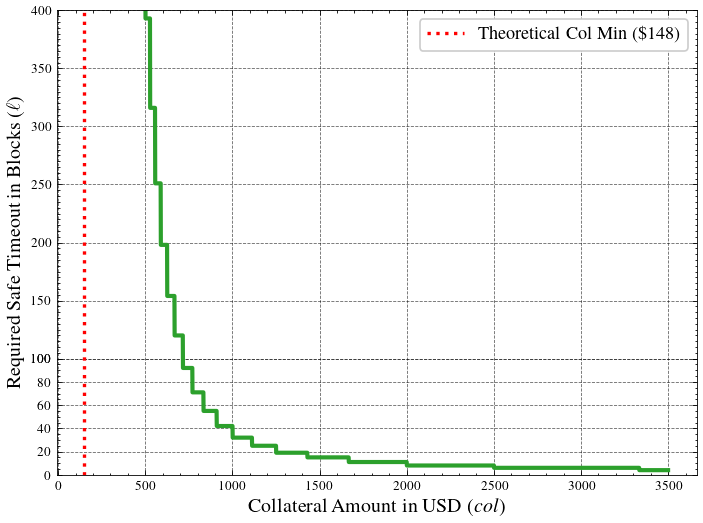

In [96]:
### This code is particularly for evaluating he-htlc.

def plot_collateral_vs_timeout(fixed_dep, fee_A, T1, miners):
    """
    Plots the relationship between Collateral and Timeout, explicitly calculating
    and displaying the theoretical lower bound for Collateral.
    """
    N = len(miners)
    plt.style.use(['science',  'grid']) ## Use together with the scienceplots library. If the Magic Block above is used, this line should be commented out to avoid conflicts.
    # plt.rcParams['text.usetex'] = False 
    # 1. Calculate the Theoretical Minimum Collateral
    col_min_theoretical = (fixed_dep / (N - 1)) + fee_A
    
    print(f"--- Analysis for Deposit: \\${fixed_dep:,.0f} ---")
    print(f"Total Miners (N): {N}")
    print(f"Absolute Minimum Collateral Required: \\${col_min_theoretical:,.2f}")
    
    # 2. Generate a smart X-axis (Collateral range)
    # We start just slightly above the theoretical minimum (e.g., +1%) 
    # to avoid plotting 'infinity', and sweep up to 5x the minimum.
    start_col = col_min_theoretical + 10
    end_col = fixed_dep * 0.35
    col_range = np.linspace(start_col, end_col, num=3000)
    
    T_values = []
    
    # 3. Calculate safe T for each collateral value
    for col in col_range:
        # Using the standard Two-Phase function (escalating=False, d1=False)
        T = calculate_two_phase_T(fixed_dep, fee_A, col, T1, miners, d1=False, he=True) - T1
        T_values.append(T)
        
    # --- 4. Plotting ---
    plt.figure(figsize=(6, 4.5), dpi=120)
    
    # The main curve
    plt.plot(col_range, T_values, color='#2ca02c', linewidth=2.5)
    
    # The Vertical Asymptote (Theoretical Col_Min)
    plt.axvline(x=col_min_theoretical, color='red', linestyle=':', linewidth=2,
                label=f'Theoretical Col Min (\\${col_min_theoretical:,.0f})')
    
    # # The Horizontal Floor (T1)
    # plt.axhline(y=T1, color='gray', linestyle='--', linewidth=1.5, 
    #             label=f'Absolute T Min (Phase 1 = {T1} blocks)')

    plt.ylim(0,400)
    ticks = list(range(0, 101, 20)) + list(range(100, 401, 50))
    plt.yticks(ticks)

    # Formatting
    # plt.title('He-HTLC: Collateral and Minimum Timeout', fontsize=14, fontweight='bold')
    plt.xlabel('Collateral Amount in USD ($col$)', fontsize=12)
    plt.ylabel('Required Safe Timeout in Blocks ($\ell$)', fontsize=12)
    
    # Optional: use a log scale for Y-axis if the initial T values are massive
    # plt.yscale('log') 
    
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper right', fontsize=11)
    plt.tight_layout()
    plt.savefig('he-htlc.pdf', format='pdf', bbox_inches='tight')    
    plt.show()

# ==========================================
# How to run it:
# ==========================================
plot_collateral_vs_timeout(fixed_dep=10000, fee_A=1.0, T1=12, miners=real_distribution)

In [ ]:
# Playground for running single protocol evaluations
# ==========================================
if __name__ == "__main__":
    # miners = get_mining_distribution()
    distri = real_distribution
    # print("Mining Distribution:", [round(100*p, 4) for p in distri])
    print("Max power:", round(max(distri), 4))
    print("Total power:", round(sum(distri), 4))
    print("-" * 40)
    
    N = len(distri)
    # Test variables
    dep = 10000.0  # Bribe amount
    feeA = 1       # Punishment (e.g., missed standard fees/block reward risk)
    
    # print(f"Deposit (Bribe): {dep}, FeeA: {feeA}")
    
    # print("\n      Bribe: Final - timelock bribing")
    # print("==========================")
    # T_approx = calculate_approx_T(dep, feeA, distri)
    # print(f"Approximation Bound T: {T_approx}")
    
    # # T_exact = calculate_exact_T_bribe_final(dep, feeA, distri)
    # # print(f"Exact lower bound T: {T_exact}")

    # print("\n      Bribe: Agnostic - first phase set as 12 blocks (2 hours)")
    # print("==========================")
    # print("______He-HTLC______")
    # col1 = (dep / 20) + feeA
    # T_he1 = calculate_two_phase_T(dep, feeA, col1, 12, distri, d1=False, he=True) 
    # col2 = (dep / 10) + feeA
    # T_he2 = calculate_two_phase_T(dep, feeA, col2, 12, distri, d1=False, he=True)
    # col3 = (dep / 5) + feeA
    # T_he3 = calculate_two_phase_T(dep, feeA, col3, 12, distri, d1=False, he=True)
    # print(f"He-HTLC timeouts with different collaterals: Collateral_1 ({col1:,.2f}): {T_he1} blocks, Collateral_2: {col2:,.2f}: {T_he2} blocks, Collateral_3: {col3:,.2f}: {T_he3} blocks")
    # print("______monolithic pun______")
    # T_base = calculate_two_phase_T(dep, feeA, 0, 12, distri, d1=False, he=False) 
    # print(f"Base (no collateral, no d1) lower bound T: {T_base}")
    # T_frame0 = calculate_two_phase_T(dep, feeA, 0, 12, distri, d1=True, he=False)
    # print(f"Neon (d1=1, no collateral) lower bound T: {T_frame0}")
    # T_frame1 = calculate_two_phase_T(dep, feeA, col1, 12, distri, d1=True, he=False)
    # print(f"Neon (d1=1, collateral_1: {col1:,.2f}) lower bound T: {T_frame1}")
    # T_frame2 = calculate_two_phase_T(dep, feeA, col2, 12, distri, d1=True, he=False)
    # print(f"Neon (d1=1, collateral_2: {col2:,.2f}) lower bound T: {T_frame2}")
    # T_frame3 = calculate_two_phase_T(dep, feeA, col3, 12, distri, d1=True, he=False)
    # print(f"Neon (d1=1, collateral_3: {col3:,.2f}) lower bound T: {T_frame3} blocks")
    # print("\n______escalating pun loose bound______")
    # T_escalating0 = calculate_two_phase_T(dep, feeA, 0, 12, distri, d1=True, he=False, escalating=True)
    # T_escalating1 = calculate_two_phase_T(dep, feeA, col1, 12, distri, d1=True, he=False, escalating=True)
    # T_escalating2 = calculate_two_phase_T(dep, feeA, col2, 12, distri, d1=True, he=False, escalating=True)
    # T_escalating3 = calculate_two_phase_T(dep, feeA, col3, 12, distri, d1=True, he=False, escalating=True)
    # print(f"Neon escalating - no collateral: {T_escalating0}, collateral_1: {T_escalating1}, collateral_2: {T_escalating2}, collateral_3: {T_escalating3} blocks")
    # print("\n______escalating pun expectation calculation______")
    # T_esc_exp0 = calculate_two_phase_T(dep, feeA, 0, 12, distri, d1=True, he=False, escalating=True, esc_tight=True)
    # T_esc_exp1 = calculate_two_phase_T(dep, feeA, col1, 12, distri, d1=True, he=False, escalating=True, esc_tight=True)
    # T_esc_exp2 = calculate_two_phase_T(dep, feeA, col2, 12, distri, d1=True, he=False, escalating=True, esc_tight=True)
    # T_esc_exp3 = calculate_two_phase_T(dep, feeA, col3, 12, distri, d1=True, he=False, escalating=True, esc_tight=True)
    # print(f"Neon escalating (expectation) - no collateral: {T_esc_exp0}, collateral_1: {T_esc_exp1}, collateral_2: {T_esc_exp2}, collateral_3: {T_esc_exp3} blocks")
    T_esc_exp_max = calculate_two_phase_T(1420000000000, feeA, 0, 12, distri, d1=True, he=False, escalating=True, esc_tight=True)
    print(f"Neon escalating (expectation) for maximum deposit of 1.42 trillion USD with collateral of 50: {T_esc_exp_max} blocks")

In [48]:
# This function runs the full set of experiments for the specified protocols and saves the results to CSV files.
def run_experiments(global_params, protocols_list, dep_values):
    """
    Loops through the requested protocols and saves each to its own CSV file.
    """
    os.makedirs('data-de', exist_ok=True)
    fee_A = global_params['fee_A']
    miners = global_params['miners']
    T1 = global_params['T1']
    
    for protocol in protocols_list:
        name = protocol['name']
        p_type = protocol['type']
        filepath = os.path.join('data-de', f"{name}.csv")
        
        print(f"Running '{name}'...")
        results = []
        
        for dep in dep_values:
            T_result = None
            
            # --- Switchboard ---
            if p_type == 'approx': # For FB-HTLC approximation, not used in current experiments.
                T_result = calculate_approx_T(dep, fee_A, miners)
            # elif p_type == 'tight': # For FB-HTLC recursive search, not used in current experiments.
            #     T_result = calculate_exact_T_bribe_final(dep, fee_A, miners)
            elif p_type == 'two_phase':
                # Handle dynamic collateral ratio OR flat collateral
                if 'col_ratio' in protocol:
                    # col = (dep * protocol['col_ratio']) + fee_A ## Here we could be wrong, it's better to set col just by proportion and then calculate the kappa out of col and feeA, and search reversely for the corresponding T. 
                    col = (dep * protocol['col_ratio']) 
                else:
                    col = protocol.get('col', 0.0) # Default to 0 if not provided
                
                # Extract boolean flags (defaulting to False if not specified)
                d1 = protocol.get('d1', False)
                he = protocol.get('he', False)
                escalating = protocol.get('escalating', False)
                esc_tight = protocol.get('esc_tight', False)
                
                T_result = calculate_two_phase_T(
                    dep, fee_A, col, T1, miners, 
                    d1=d1, he=he, escalating=escalating, esc_tight=esc_tight
                )
            else:
                raise ValueError(f"Unknown protocol type: {p_type}")
                
            # Format infinity for CSV saving
            str_T = "inf" if T_result == float('inf') else str(T_result)
            results.append({"Deposit_USD": dep, "Safe_T": str_T})
            # early stopping for infinite T to save time and resources
            if T_result == float('inf') and not 'col_ratio' in protocol:
                print(f"  Reached infinite T at deposit {dep}. Stopping further calculations for this protocol.")
                break

            
        # Write to dedicated CSV
        with open(filepath, mode='w', newline='') as csvfile:
            writer = csv.DictWriter(csvfile, fieldnames=["Deposit_USD", "Safe_T"])
            writer.writeheader()
            writer.writerows(results)
            
    print("\n All requested experiments generated and saved to the 'data-de/' folder.")

# ==========================================
# 4. Execution Dashboard
# ==========================================
if __name__ == "__main__":
    
    # 1. Global Parameters
    GLOBAL_PARAMS = {
        'fee_A': 1.0,               
        'T1': 12,    # Matched to your playground (12 blocks)             
        'miners': real_distribution # load distribution earlier
    }
    
    # 2. Deposit Array ($10 to $100,000)
    dep_values = [round(d, 2) for d in np.logspace(1, 5, num=500)]
    
    # 3. Master Protocol List
    # You can comment out the ones you don't want to run today.
    PROTOCOLS_TO_RUN = [
        # # --- Baselines ---
        # {'name': 'IC_HTLC_Approx', 'type': 'approx'},
        
        # # # --- He-HTLC (Using col_ratio to match playground) ---
        {'name': 'He_HTLC_col5pct',  'type': 'two_phase', 'col_ratio': 0.05, 'he': True},
        {'name': 'He_HTLC_col10pct', 'type': 'two_phase', 'col_ratio': 0.10, 'he': True},
        {'name': 'He_HTLC_col20pct', 'type': 'two_phase', 'col_ratio': 0.20, 'he': True},

        # --- He-HTLC with Flat Collateral ---
        # {'name': 'He_HTLC_col10_flat', 'type': 'two_phase', 'col': 10.0, 'he': True},
        # {'name': 'He_HTLC_col50_flat', 'type': 'two_phase', 'col': 50.0, 'he': True},
        # {'name': 'He_HTLC_col20_flat', 'type': 'two_phase', 'col': 20.0, 'he': True},        

        # # --- Neon Monolithic (No Escalation) ---
        # {'name': 'Neon_Mono_col0',     'type': 'two_phase', 'col': 0.0, 'd1': True},
        # {'name': 'Neon_Mono_col20',    'type': 'two_phase', 'col': 20.0, 'd1': True},
        # {'name': 'Neon_Mono_col50',    'type': 'two_phase', 'col': 50.0, 'd1': True},
        # {'name': 'Neon_Mono_col2pct',  'type': 'two_phase', 'col_ratio': 0.02, 'd1': True},
        # {'name': 'Neon_Mono_col5pct',  'type': 'two_phase', 'col_ratio': 0.05, 'd1': True},
        # {'name': 'Neon_Mono_col10pct', 'type': 'two_phase', 'col_ratio': 0.10, 'd1': True},
        # {'name': 'Neon_Mono_col20pct', 'type': 'two_phase', 'col_ratio': 0.20, 'd1': True},
        
        # # --- Neon Escalating (Loose Math) ---
        # {'name': 'Neon_Esc_Loose_col0',    'type': 'two_phase', 'col': 0.0, 'd1': True, 'escalating': True},
        # {'name': 'Neon_Esc_Loose_col2pct', 'type': 'two_phase', 'col_ratio': 0.02, 'd1': True, 'escalating': True},
        # {'name': 'Neon_Esc_Loose_col5pct', 'type': 'two_phase', 'col_ratio': 0.05, 'd1': True, 'escalating': True},
        
        # # --- Neon Escalating (Tight Expectation) ---
        # {'name': 'Neon_Esc_Tight_col0',    'type': 'two_phase', 'col': 0.0, 'd1': True, 'escalating': True, 'esc_tight': True},
        # {'name': 'Neon_Esc_Tight_col2pct', 'type': 'two_phase', 'col_ratio': 0.02, 'd1': True, 'escalating': True, 'esc_tight': True},
        # {'name': 'Neon_Esc_Tight_col5pct', 'type': 'two_phase', 'col_ratio': 0.05, 'd1': True, 'escalating': True, 'esc_tight': True},
        # {'name': 'Neon_Esc_Tight_col10pct', 'type': 'two_phase', 'col_ratio': 0.10, 'd1': True, 'escalating': True, 'esc_tight': True},

        # {'name': 'Neon_Esc_Tight_col50_flat', 'type': 'two_phase', 'col': 50.0, 'd1': True, 'escalating': True, 'esc_tight': True},
        # {'name': 'Neon_Esc_Tight_col20_flat', 'type': 'two_phase', 'col': 20.0, 'd1': True, 'escalating': True, 'esc_tight': True}
    
        
    ]
    
    # Run all generations
    run_experiments(GLOBAL_PARAMS, PROTOCOLS_TO_RUN, dep_values)

Running 'He_HTLC_col5pct'...
HE-HTLC Case: Calculated kappa based on col and dep is 2374.
HE-HTLC Case: Calculated kappa based on col and dep is 762.
HE-HTLC Case: Calculated kappa based on col and dep is 456.
HE-HTLC Case: At T=3055, kappa=456 meets the required kappa_target=456.
HE-HTLC Case: Calculated kappa based on col and dep is 327.
HE-HTLC Case: At T=1097, kappa=327 meets the required kappa_target=327.
HE-HTLC Case: Calculated kappa based on col and dep is 255.
HE-HTLC Case: At T=669, kappa=255 meets the required kappa_target=255.
HE-HTLC Case: Calculated kappa based on col and dep is 210.
HE-HTLC Case: At T=480, kappa=210 meets the required kappa_target=210.
HE-HTLC Case: Calculated kappa based on col and dep is 180.
HE-HTLC Case: At T=375, kappa=180 meets the required kappa_target=180.
HE-HTLC Case: Calculated kappa based on col and dep is 157.
HE-HTLC Case: At T=305, kappa=157 meets the required kappa_target=157.
HE-HTLC Case: Calculated kappa based on col and dep is 140.
HE

In [ ]:
# This function plots a big comparison graph for all the generated protocols, which is not used currently
def plot_master_comparison_acm(plot_configs, y_max=300):
    # Notice we removed the figsize here so it obeys the rcParams above!
    fig, ax = plt.subplots(dpi=150)
    plt.style.use(['science', 'ieee', 'grid']) ## Use together with the scienceplots library. If the Magic Block above is used, this line should be commented out to avoid conflicts.
    
    for config in plot_configs:
        filepath = config['filepath']
        label = config['label']
        color = config.get('color', '#000000')
        linestyle = config.get('linestyle', '-')
        
        if not os.path.exists(filepath):
            continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            reader = csv.DictReader(csvfile)
            for row in reader:
                dep = float(row['Deposit_USD'])
                t_val = row['Safe_T']
                if t_val == 'inf':
                    x_deps.append(dep)
                    y_timeouts.append(y_max * 5)
                    break 
                else:
                    t_float = float(t_val)
                    x_deps.append(dep)
                    y_timeouts.append(t_float)
                    if t_float > y_max * 5: break
                        
        ax.plot(x_deps, y_timeouts, label=label, color=color, linestyle=linestyle)

    # ==========================================
    # Formatting and Aesthetics
    # ==========================================
    ax.set_ylim(0, y_max)
    ax.set_xscale('log')
    
    # Format X-axis with dollar signs properly escaped for LaTeX
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    
    # NO TITLE! Academic papers use \caption{} in the LaTeX document instead.
    ax.set_xlabel(r'Deposit Amount (USD)')
    ax.set_ylabel(r'Total Safe Timeout ($T$ blocks)')
    
    # # Red shading for infinity/failure
    # ax.axhspan(y_max * 0.95, y_max, color='red', alpha=0.1)

    # Clean, subtle academic grid
    ax.grid(True, which='major', linestyle='-', alpha=0.3)
    
    # Despining (Removing top and right borders)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Place legend outside the plot area so it doesn't cover data!
    # ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, ncol=1, fontsize=6)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25), ncol=3, fontsize=6, frameon=True)

    
    # Save as crisp PDF vector graphic!
    plt.savefig('HTLC_Master_Overview.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# ==========================================
# The "Everything" Configuration (LaTeX Escaped!)
# ==========================================
if __name__ == "__main__":
    
    # NOTICE: All % signs are changed to \% so LaTeX doesn't crash!
    all_files_config = [
        # Baseline
        {'filepath': 'data/IC_HTLC_Approx.csv', 'label': 'Baseline: Approx', 'color': 'black', 'linestyle': ':'},
        
        # He-HTLC
        {'filepath': 'data/He_HTLC_col5pct.csv', 'label': r'He-HTLC (5\% Col)', 'color': '#ff7f0e', 'linestyle': '--'},
        {'filepath': 'data/He_HTLC_col10pct.csv', 'label': r'He-HTLC (10\% Col)', 'color': '#d62728', 'linestyle': '--'},
        {'filepath': 'data/He_HTLC_col20pct.csv', 'label': r'He-HTLC (20\% Col)', 'color': '#9467bd', 'linestyle': '--'},
        {'filepath': 'data/He_HTLC_col20_flat.csv', 'label': r'He-HTLC (Flat \$20)', 'color': '#d62728', 'linestyle': '-.'},
        # {'filepath': 'data/He_HTLC_col50_flat.csv', 'label': r'He-HTLC (Flat \$50)', 'color': '#ff7f0e', 'linestyle': '-.'},
        
        # Neon Mono
        {'filepath': 'data/Neon_Mono_col0.csv', 'label': r'Neon Mono (0 Col)', 'color': '#e377c2', 'linestyle': '-'},
        {'filepath': 'data/Neon_Mono_col5pct.csv', 'label': r'Neon Mono (5\% Col)', 'color': '#8c564b', 'linestyle': '-'},
        
        # Neon Esc Loose
        # {'filepath': 'data/Neon_Esc_Loose_col0.csv', 'label': r'Neon Esc Loose (0 Col)', 'color': '#17becf', 'linestyle': '--'},
        # {'filepath': 'data/Neon_Esc_Loose_col5pct.csv', 'label': r'Neon Esc Loose (5\% Col)', 'color': '#bcbd22', 'linestyle': '--'},
        
        # Neon Esc Tight
        {'filepath': 'data/Neon_Esc_Tight_col0.csv', 'label': r'Neon Esc Tight (0 Col)', 'color': '#1f77b4', 'linestyle': '-'},
        # {'filepath': 'data/Neon_Esc_Tight_col5pct.csv', 'label': r'Neon Esc Tight (5\% Col)', 'color': '#2ca02c', 'linestyle': '-'},
        # {'filepath': 'data/Neon_Esc_Tight_col20_flat.csv', 'label': r'Neon Esc Tight (Flat \$20)', 'color': '#1f77b4', 'linestyle': '-.'},
        # {'filepath': 'data/Neon_Esc_Tight_col50_flat.csv', 'label': r'Neon Esc Tight (Flat \$50)', 'color': '#2ca02c', 'linestyle': '-.'},

        # Neon Agnostic
        # {'filepath': 'data/Neon_Agnostic_col0.csv', 'label': r'Neon Agnostic (0 Col)', 'color': '#e377c2', 'linestyle': ':'},
        # {'filepath': 'data/Neon_Agnostic_col20_flat.csv', 'label': r'Neon Agnostic (Flat \$20)', 'color': '#9467bd', 'linestyle': ':'}
        # {'filepath': 'data/Neon_Agnostic_col5pct.csv', 'label': r'Neon Agnostic (5\% Col)', 'color': '#8c564b', 'linestyle': ':'}
    ]
    
    plot_master_comparison_acm(all_files_config, y_max=350)

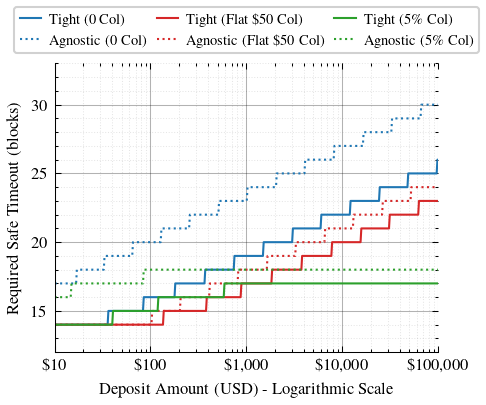

In [17]:
# This function plots the comparison graph for the escalation protocols with different bounds, which is one of the main figures used in the evaluation.
def plot_escalation_comparison(plot_configs, y_max=50):
    fig, ax = plt.subplots(dpi=150)
    plt.style.use(['science', 'ieee', 'grid']) ## Use together with the scienceplots library. If the Magic Block above is used, this line should be commented out to avoid conflicts.
    
    
    for config in plot_configs:
        filepath = config['filepath']
        label = config['label']
        color = config.get('color', '#000000')
        linestyle = config.get('linestyle', '-')
        
        if not os.path.exists(filepath):
            print(f" Missing: {filepath}")
            continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            reader = csv.DictReader(csvfile)
            for row in reader:
                dep = float(row['Deposit_USD'])
                t_val = row['Safe_T']
                if t_val != 'inf':
                    x_deps.append(dep)
                    y_timeouts.append(float(t_val))
                        
        ax.plot(x_deps, y_timeouts, label=label, color=color, linestyle=linestyle)

    # ==========================================
    # Formatting
    # ==========================================
    # Zoomed in Y-Axis!
    # ax.set_ylim(0, y_max)
    ax.set_ylim(12, 33)
    ax.set_xscale('log')
    ax.set_xlim(10, 100000)
    
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    
    ax.set_xlabel(r'Deposit Amount (USD) - Logarithmic Scale')
    ax.set_ylabel(r'Required Safe Timeout (blocks)')

    ax.grid(True, which='major', linestyle='-', alpha=0.3)
    ax.grid(True, which='minor', linestyle=':', alpha=0.1)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Legend: 3 columns, placed at the top center to save space
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.22), ncol=3, framealpha=0.9, fontsize=7, columnspacing=0.7, handletextpad=0.5, handlelength=1.5)
    
    plt.savefig('Neon_Escalation-decentralized.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# ==========================================
# The 9-Protocol Configuration Matrix
# ==========================================
if __name__ == "__main__":
    
    escalation_configs = [
        # --- 0 Collateral (BLUES) ---
        {'filepath': 'data-de/Neon_Esc_Tight_col0.csv',    'label': r'Tight (0 Col)',    'color': '#1f77b4', 'linestyle': '-'},
        # {'filepath': 'data2/Neon_Esc_Loose_col0.csv',    'label': r'Loose (0 Col)',    'color': '#1f77b4', 'linestyle': '--'},
        {'filepath': 'data-de/Neon_Agnostic_col0.csv',     'label': r'Agnostic (0 Col)', 'color': '#1f77b4', 'linestyle': ':'},
        
        # --- Flat $50 Collateral (REDS) ---
        {'filepath': 'data-de/Neon_Esc_Tight_col50_flat.csv','label': r'Tight (Flat \$50 Col)',   'color': '#d62728', 'linestyle': '-'},
        {'filepath': 'data-de/Neon_Agnostic_col50_flat.csv', 'label': r'Agnostic (Flat \$50 Col)','color': '#d62728', 'linestyle': ':'},

        # --- 5% Collateral (GREENS) ---
        {'filepath': 'data-de/Neon_Esc_Tight_col5pct.csv', 'label': r'Tight (5\% Col)',  'color': '#2ca02c', 'linestyle': '-'},
        # {'filepath': 'data2/Neon_Esc_Loose_col5pct.csv', 'label': r'Loose (5\% Col)',  'color': '#2ca02c', 'linestyle': '--'},
        {'filepath': 'data-de/Neon_Agnostic_col5pct.csv',  'label': r'Agnostic (5\% Col)','color': '#2ca02c', 'linestyle': ':'},

        # # --- Flat $20 Collateral (PURPLE) ---
        # {'filepath': 'data2/Neon_Esc_Tight_col20_flat.csv','label': r'Tight (Flat \$20 Col)',   'color': '#9467bd', 'linestyle': '-'},
        # {'filepath': 'data2/Neon_Agnostic_col20_flat.csv', 'label': r'Agnostic (Flat \$20 Col)','color': '#9467bd', 'linestyle': ':'},
    ]
    
    plot_escalation_comparison(escalation_configs, y_max=50)

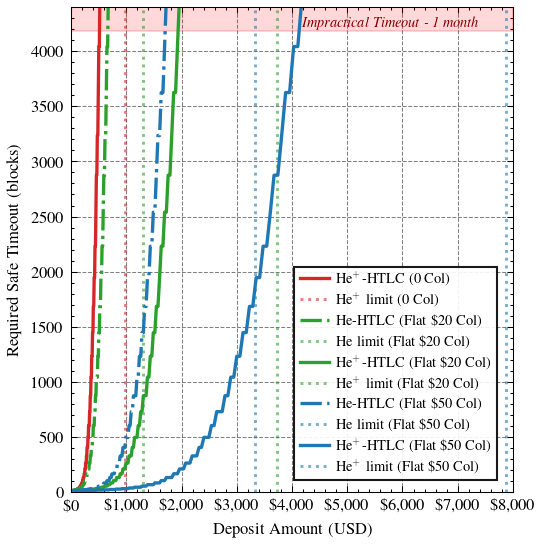

In [84]:
# This function plots the comparison graph for the two-phase protocols with fixed collaterals or zero collateral, which is one of the main figures used in the evaluation.
def plot_legacy_failures_linear(plot_configs, y_max=600, x_max=4000):
    plt.style.use(['science', 'ieee', 'grid'])
    # Keeping it slightly tall to emphasize the vertical wall
    fig, ax = plt.subplots(figsize=(3.8, 4.2), dpi=150) 
    
    for config in plot_configs:
        filepath = config['filepath']
        if not os.path.exists(filepath): continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            for row in csv.DictReader(csvfile):
                dep, t_val = float(row['Deposit_USD']), row['Safe_T']
                
                # If we exceed our X-axis limit, stop plotting this line
                if dep > x_max:
                    break
                    
                if t_val == 'inf':
                    x_deps.append(dep); y_timeouts.append(y_max * 5); break 
                else:
                    t_float = float(t_val)
                    x_deps.append(dep); y_timeouts.append(t_float)
                    if t_float > y_max * 5: break
                        
        ax.plot(x_deps, y_timeouts, label=config['label'], color=config.get('color', '#000'), 
                linestyle=config.get('linestyle', '-'), linewidth=1.6)
        # Draw the theoretical vertical asymptote if it exists
        if 'limit' in config:
            ax.axvline(x=config['limit'], color=config.get('color'), 
                       linestyle=':', linewidth=1.4, alpha=0.6, label=config.get('limit_label', None))

    # ==========================================
    # Formatting (LINEAR X-AXIS)
    # ==========================================
    ax.set_ylim(0, y_max)
    
    # Linear scale from $0 to $4,000. 
    # (The $50 collateral hits infinity at ~$3,300, so $4,000 is a perfect cutoff)
    ax.set_xlim(0, x_max) 
    
    # Format X-axis ticks to look like "$1,000", "$2,000", etc.
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    
    ax.set_xlabel(r'Deposit Amount (USD)')
    ax.set_ylabel(r'Required Safe Timeout (blocks)')
    
    # Restore the "Impractical Timeout" Red Zone at the top
    ax.axhspan(y_max * 0.95, y_max, color='red', alpha=0.15)
    
    # Position the text slightly to the right of the Y-axis so it doesn't overlap the line
    ax.text(x=x_max * 0.52, y=y_max * 0.960, s=r'\textit{Impractical Timeout - 1 month}', color='darkred', fontsize=7)

    ax.legend(loc='lower right', bbox_to_anchor=(0.98, 0.01), framealpha=0.9, edgecolor='black', fancybox=False, fontsize=7, handletextpad=0.5)
    
    plt.savefig('HTLC_Legacy_Dep_Time.pdf', format='pdf', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    legacy_configs = [
        {'filepath': 'data69/Neon_Mono_col0.csv',    'label': r'He$^+$-HTLC (0 Col)', 'color': '#d62728', 'linestyle': '-', 'limit': 973, 'limit_label': r'He$^+$ limit (0 Col)'},
        {'filepath': 'data69/He_HTLC_col20_flat.csv', 'label': r'He-HTLC (Flat \$20 Col)',          'color': '#2ca02c', 'linestyle': '-.', 'limit': 1292, 'limit_label': r'He limit (Flat \$20 Col)'},
        {'filepath': 'data69/Neon_Mono_col20.csv',   'label': r'He$^+$-HTLC (Flat \$20 Col)',     'color': '#2ca02c', 'linestyle': '-', 'limit': 3733, 'limit_label': r'He$^+$ limit (Flat \$20 Col)'},
        {'filepath': 'data69/He_HTLC_col50_flat.csv', 'label': r'He-HTLC (Flat \$50 Col)',          'color': '#1f77b4', 'linestyle': '-.', 'limit': 3332, 'limit_label': r'He limit (Flat \$50 Col)'},
        {'filepath': 'data69/Neon_Mono_col50.csv',   'label': r'He$^+$-HTLC (Flat \$50 Col)',     'color': '#1f77b4', 'linestyle': '-', 'limit': 7873, 'limit_label': r'He$^+$ limit (Flat \$50 Col)'}
    ]
    
    # Capped at $4,000 because the lines will all be dead by then!
    plot_legacy_failures_linear(legacy_configs, y_max=4400, x_max=8000)

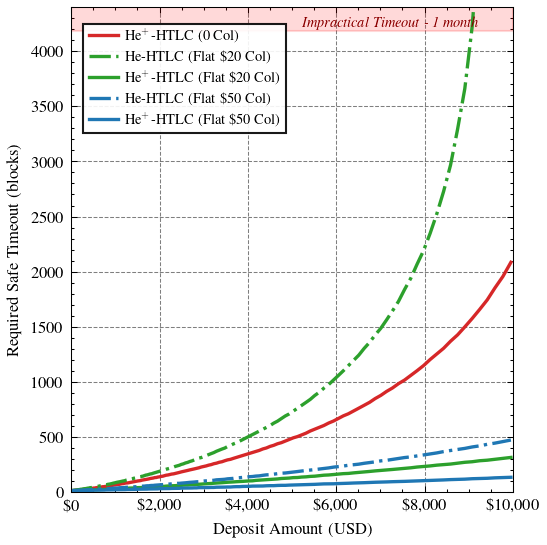

In [49]:
# This function plots the comparison graph for the two-phase protocols with fixed collaterals or zero collateral, which is one of the main figures used in the evaluation.
def plot_legacy_failures_linear(plot_configs, y_max=600, x_max=4000):
    plt.style.use(['science', 'ieee', 'grid'])
    # Keeping it slightly tall to emphasize the vertical wall
    fig, ax = plt.subplots(figsize=(3.8, 4.2), dpi=150) 
    
    for config in plot_configs:
        filepath = config['filepath']
        if not os.path.exists(filepath): continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            for row in csv.DictReader(csvfile):
                dep, t_val = float(row['Deposit_USD']), row['Safe_T']
                
                # If we exceed our X-axis limit, stop plotting this line
                if dep > x_max:
                    break
                    
                if t_val == 'inf':
                    x_deps.append(dep); y_timeouts.append(y_max * 5); break 
                else:
                    t_float = float(t_val)
                    x_deps.append(dep); y_timeouts.append(t_float)
                    if t_float > y_max * 5: break
                        
        ax.plot(x_deps, y_timeouts, label=config['label'], color=config.get('color', '#000'), 
                linestyle=config.get('linestyle', '-'), linewidth=1.6)


    # ==========================================
    # Formatting (LINEAR X-AXIS)
    # ==========================================
    ax.set_ylim(0, y_max)
    
    # Linear scale from $0 to $4,000. 
    # (The $50 collateral hits infinity at ~$3,300, so $4,000 is a perfect cutoff)
    ax.set_xlim(0, x_max) 
    
    # Format X-axis ticks to look like "$1,000", "$2,000", etc.
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    
    ax.set_xlabel(r'Deposit Amount (USD)')
    ax.set_ylabel(r'Required Safe Timeout (blocks)')
    
    # Restore the "Impractical Timeout" Red Zone at the top
    ax.axhspan(y_max * 0.95, y_max, color='red', alpha=0.15)
    
    # Position the text slightly to the right of the Y-axis so it doesn't overlap the line
    ax.text(x=x_max * 0.52, y=y_max * 0.960, s=r'\textit{Impractical Timeout - 1 month}', color='darkred', fontsize=7)

    ax.legend(loc='upper left', bbox_to_anchor=(0.01, 0.98), framealpha=0.9, edgecolor='black', fancybox=False, fontsize=7, handletextpad=0.5)
    
    plt.savefig('HTLC_Legacy_Dep_Time-decentralized.pdf', format='pdf', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    legacy_configs = [
        {'filepath': 'data-de/Neon_Mono_col0.csv',    'label': r'He$^+$-HTLC (0 Col)', 'color': '#d62728', 'linestyle': '-', 'limit': 966, 'limit_label': r'He$^+$ limit (0 Col)'},
        {'filepath': 'data-de/He_HTLC_col20_flat.csv', 'label': r'He-HTLC (Flat \$20 Col)',          'color': '#2ca02c', 'linestyle': '-.', 'limit': 1292, 'limit_label': r'He limit (Flat \$20 Col)'},
        {'filepath': 'data-de/Neon_Mono_col20.csv',   'label': r'He$^+$-HTLC (Flat \$20 Col)',     'color': '#2ca02c', 'linestyle': '-', 'limit': 3726, 'limit_label': r'He$^+$ limit (Flat \$20 Col)'},
        {'filepath': 'data-de/He_HTLC_col50_flat.csv', 'label': r'He-HTLC (Flat \$50 Col)',          'color': '#1f77b4', 'linestyle': '-.', 'limit': 3332, 'limit_label': r'He limit (Flat \$50 Col)'},
        {'filepath': 'data-de/Neon_Mono_col50.csv',   'label': r'He$^+$-HTLC (Flat \$50 Col)',     'color': '#1f77b4', 'linestyle': '-', 'limit': 7866, 'limit_label': r'He$^+$ limit (Flat \$50 Col)'}
    ]
    
    # Capped at $4,000 because the lines will all be dead by then!
    plot_legacy_failures_linear(legacy_configs, y_max=4400, x_max=10000)

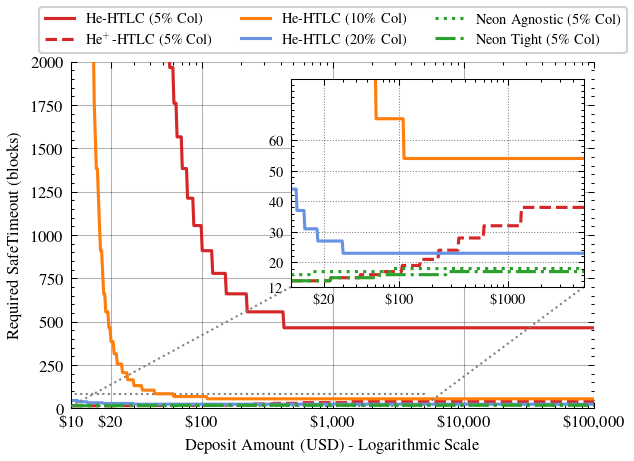

In [29]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

def plot_percentage_collaterals_inset(plot_configs, y_max=400):
    plt.style.use(['science', 'ieee', 'grid'])
    fig, ax = plt.subplots(figsize=(4.5, 3.0), dpi=150) 
    
    # 1. Create the Inset Axis
    # [x0, y0, width, height] as fractions of the main plot
    # We place it in the middle-right where there is lots of empty space
    axins = ax.inset_axes([0.42, 0.35, 0.56, 0.6])
    
    for config in plot_configs:
        filepath = config['filepath']
        if not os.path.exists(filepath): continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            for row in csv.DictReader(csvfile):
                dep, t_val = float(row['Deposit_USD']), row['Safe_T']
                if t_val == 'inf':
                    x_deps.append(dep); y_timeouts.append(y_max * 5); continue
                else:
                    t_float = float(t_val)
                    x_deps.append(dep); y_timeouts.append(t_float)
                    # if t_float > y_max * 5: break
                        
        # 2. Plot on BOTH the main axis and the inset axis
        ax.plot(x_deps, y_timeouts, label=config['label'], color=config.get('color', '#000'), 
                linestyle=config.get('linestyle', '-'), linewidth=1.5)
        
        axins.plot(x_deps, y_timeouts, color=config.get('color', '#000'), 
                   linestyle=config.get('linestyle', '-'), linewidth=1.5)

    # ==========================================
    # Main Axis Formatting
    # ==========================================
    ax.set_ylim(0, y_max)
    ax.set_xlim(10, 100000)
    ax.set_xscale('log')
    ax.set_xticks([10, 20, 100, 1000, 10000, 100000])
    
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    ax.set_xlabel(r'Deposit Amount (USD) - Logarithmic Scale')
    ax.set_ylabel(r'Required SafeTimeout (blocks)')
    
    ax.grid(True, which='major', linestyle='-', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Place legend at upper left to stay away from the inset box
    # ax.legend(loc='upper left', framealpha=0.9, edgecolor='black', fancybox=False, fontsize=8)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.18), 
            framealpha=0.9, ncol=3, fontsize=7)
    
    # ==========================================
    # Inset Axis Formatting (The 0-50 Zoom)
    # ==========================================
    axins.set_xlim(10, 5000) # Keep same X scale
    axins.set_xscale('log')
    axins.set_ylim(12, 80)      # ZOOM IN ON Y: 0 to 50 blocks!
    
    # Clean up the inset grid and ticks
    axins.grid(True, linestyle=':', alpha=0.5)
    axins.set_yticks([ 12, 20, 30, 40, 50, 60])
    axins.set_yticklabels([12, 20, 30, 40, 50, 60], fontsize=7)
    axins.set_xticks([ 20, 100, 1000])
    
    # Hide X-axis labels on the inset so it doesn't look cluttered
    axins.set_xticklabels([r'\$20', r'\$100', r'\$1000'], fontsize=7) 
    
    # 3. Draw the lines connecting the zoom box to the main axes
    # loc1 and loc2 are the corners to draw lines from (3=lower left, 4=lower right)
    mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="0.5", linestyle=':')
    
    plt.savefig('HTLC_Percentage_Collaterals-519.pdf', format='pdf', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    pct_configs = [
        {'filepath': 'data519/He_HTLC_col5pct.csv',  'label': r'He-HTLC (5\% Col)',  'color': '#d62728', 'linestyle': '-'},
        {'filepath': 'data519/Neon_Mono_col5pct.csv', 'label': r'He$^+$-HTLC (5\% Col)', 'color': '#d62728', 'linestyle': '--'},
        {'filepath': 'data519/He_HTLC_col10pct.csv', 'label': r'He-HTLC (10\% Col)', 'color': '#ff7f0e', 'linestyle': '-'},
        {'filepath': 'data519/He_HTLC_col20pct.csv', 'label': r'He-HTLC (20\% Col)', 'color': "#6893e2", 'linestyle': '-'},
        {'filepath': 'data519/Neon_Agnostic_col5pct.csv', 'label': r'Neon Agnostic (5\% Col)', 'color': '#2ca02c', 'linestyle': ':'},
        {'filepath': 'data519/Neon_Esc_Tight_col5pct.csv', 'label': r'Neon Tight (5\% Col)', 'color': '#2ca02c', 'linestyle': '-.'},
    ]
    
    plot_percentage_collaterals_inset(pct_configs, y_max=2000)

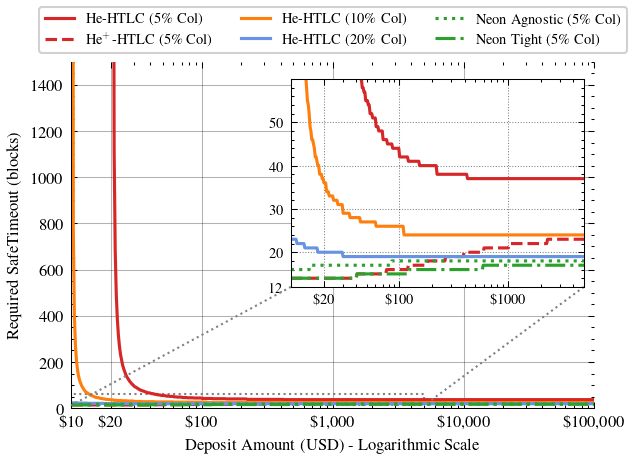

In [72]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

def plot_percentage_collaterals_inset(plot_configs, y_max=400):
    plt.style.use(['science', 'ieee', 'grid'])
    fig, ax = plt.subplots(figsize=(4.5, 3.0), dpi=150) 
    
    # 1. Create the Inset Axis
    # [x0, y0, width, height] as fractions of the main plot
    # We place it in the middle-right where there is lots of empty space
    axins = ax.inset_axes([0.42, 0.35, 0.56, 0.6])
    
    for config in plot_configs:
        filepath = config['filepath']
        if not os.path.exists(filepath): continue
            
        x_deps, y_timeouts = [], []
        
        with open(filepath, mode='r') as csvfile:
            for row in csv.DictReader(csvfile):
                dep, t_val = float(row['Deposit_USD']), row['Safe_T']
                if t_val == 'inf':
                    x_deps.append(dep); y_timeouts.append(y_max * 5); continue
                else:
                    t_float = float(t_val)
                    x_deps.append(dep); y_timeouts.append(t_float)
                    # if t_float > y_max * 5: break
                        
        # 2. Plot on BOTH the main axis and the inset axis
        ax.plot(x_deps, y_timeouts, label=config['label'], color=config.get('color', '#000'), 
                linestyle=config.get('linestyle', '-'), linewidth=1.5)
        
        axins.plot(x_deps, y_timeouts, color=config.get('color', '#000'), 
                   linestyle=config.get('linestyle', '-'), linewidth=1.5)

    # ==========================================
    # Main Axis Formatting
    # ==========================================
    ax.set_ylim(0, y_max)
    ax.set_xlim(10, 100000)
    ax.set_xscale('log')
    ax.set_xticks([10, 20, 100, 1000, 10000, 100000])
    
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"\\${int(x):,}"))
    ax.set_xlabel(r'Deposit Amount (USD) - Logarithmic Scale')
    ax.set_ylabel(r'Required SafeTimeout (blocks)')
    
    ax.grid(True, which='major', linestyle='-', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Place legend at upper left to stay away from the inset box
    # ax.legend(loc='upper left', framealpha=0.9, edgecolor='black', fancybox=False, fontsize=8)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.18), 
            framealpha=0.9, ncol=3, fontsize=7)
    
    # ==========================================
    # Inset Axis Formatting (The 0-50 Zoom)
    # ==========================================
    axins.set_xlim(10, 5000) # Keep same X scale
    axins.set_xscale('log')
    axins.set_ylim(12, 60)      # ZOOM IN ON Y: 0 to 50 blocks!
    
    # Clean up the inset grid and ticks
    axins.grid(True, linestyle=':', alpha=0.5)
    axins.set_yticks([ 12, 20, 30, 40, 50])
    axins.set_yticklabels([12, 20, 30, 40, 50], fontsize=7)
    axins.set_xticks([ 20, 100, 1000])
    
    # Hide X-axis labels on the inset so it doesn't look cluttered
    axins.set_xticklabels([r'\$20', r'\$100', r'\$1000'], fontsize=7) 
    
    # 3. Draw the lines connecting the zoom box to the main axes
    # loc1 and loc2 are the corners to draw lines from (3=lower left, 4=lower right)
    mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="0.5", linestyle=':')
    
    plt.savefig('HTLC_Percentage_Collaterals-de.pdf', format='pdf', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    pct_configs = [
        {'filepath': 'data-de/He_HTLC_col5pct.csv',  'label': r'He-HTLC (5\% Col)',  'color': '#d62728', 'linestyle': '-'},
        {'filepath': 'data-de/Neon_Mono_col5pct.csv', 'label': r'He$^+$-HTLC (5\% Col)', 'color': '#d62728', 'linestyle': '--'},
        {'filepath': 'data-de/He_HTLC_col10pct.csv', 'label': r'He-HTLC (10\% Col)', 'color': '#ff7f0e', 'linestyle': '-'},
        {'filepath': 'data-de/He_HTLC_col20pct.csv', 'label': r'He-HTLC (20\% Col)', 'color': "#6893e2", 'linestyle': '-'},
        {'filepath': 'data-de/Neon_Agnostic_col5pct.csv', 'label': r'Neon Agnostic (5\% Col)', 'color': '#2ca02c', 'linestyle': ':'},
        {'filepath': 'data-de/Neon_Esc_Tight_col5pct.csv', 'label': r'Neon Tight (5\% Col)', 'color': '#2ca02c', 'linestyle': '-.'},
    ]
    
    plot_percentage_collaterals_inset(pct_configs, y_max=1500)